# ChickenStress — 01. Pemrosesan Data (sampai sebelum modelling)
### Bagian 1 dari 4 (`01_image_processing.ipynb` → `02_models.ipynb` → `03_evaluate.ipynb` → `04_inference.ipynb`)

Notebook ini adalah pecahan dari notebook eksplorasi awal (patch tetap dipertahankan, alur tidak diubah):
1. **Dataset asli tidak disentuh** — semua proses membaca dari salinan kerja (`WORK_DIR`), bukan langsung dari folder sumber (`RAW_DIR`). Folder sumber hanya dibaca sekali untuk di-copy, tidak pernah ditulis ulang.
2. **Augmentasi & balancing hanya di train** — split train/valid/test dilakukan *sebelum* augmentasi, dan augmentasi/balancing hanya diterapkan ke folder `train`. Folder `valid` dan `test` tetap murni data asli.
3. Notebook ini berhenti **sebelum tahap modelling** (load data mentah → EDA → quality check (+ perbaikan blur via Laplacian sharpening) → deteksi sesi/burst → crop+split klasifikasi → balancing → dataset deteksi format YOLO). Eksperimen 6 konfigurasi model ada di `02_models.ipynb`, evaluasi ada di `03_evaluate.ipynb`, Image Quality Gate untuk inference/produksi (BAGIAN B alur) ada terpisah di `04_inference.ipynb`.

**PATCH baru (dataset cleanup):**
- Folder perantara `classification_dataset_raw` **dihapus dari pipeline** — crop bounding box dan split train/valid/test sekarang digabung jadi satu langkah, langsung menulis ke `WORK_DIR/dataset`. Semua folder yang tersisa (`train`/`valid`/`test` mentah, `dataset/`, `yolo_detect_dataset/`) sekarang benar-benar dipakai di `02_models.ipynb` — tidak ada lagi output yang nganggur.
- Ditambahkan **Quality Check** (RGB/non-RGB, file corrupt, mismatch ukuran metadata vs aktual, deteksi blur) sebelum data diproses lebih lanjut.
- Di akhir notebook ada cell yang menyimpan semua path/variabel penting (`class_to_id`, `train_df`/`valid_df`/`test_df`, dst.) ke `WORK_DIR/pipeline_artifacts.pkl`, supaya `02_models.ipynb` dan `03_evaluate.ipynb` bisa memuat ulang tanpa mengulang proses di atas.

In [4]:
import os
import json
import random
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2

import torch

pd.set_option("display.max_columns", None)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Reproducibility seed set to", SEED)


Reproducibility seed set to 42


## 1. Lokasi Dataset

`RAW_DIR` = folder dataset asli, **hanya dibaca**, tidak pernah ditulis.
`WORK_DIR` = salinan kerja tempat semua proses (crop, augmentasi, split) dilakukan.

In [5]:
RAW_DIR = r"E:\Magang DSC\Code - Image Classification Workflow\Data"
WORK_DIR = os.path.join(os.path.dirname(RAW_DIR), "Data_working")

RAW_TRAIN_DIR = os.path.join(RAW_DIR, "train")
RAW_VALID_DIR = os.path.join(RAW_DIR, "valid")
RAW_TEST_DIR  = os.path.join(RAW_DIR, "test")

TRAIN_DIR = os.path.join(WORK_DIR, "train")
VALID_DIR = os.path.join(WORK_DIR, "valid")
TEST_DIR  = os.path.join(WORK_DIR, "test")


## 2. Copy dataset asli ke working folder

Dilakukan sekali saja (idempotent — kalau `WORK_DIR` sudah ada, tidak di-copy ulang). Setelah ini, **semua** cell berikutnya hanya membaca/menulis di `WORK_DIR`, tidak pernah menyentuh `RAW_DIR`.

In [6]:
def copy_raw_dataset(raw_dir, work_dir):
    if os.path.exists(work_dir):
        print(f"[SKIP] {work_dir} sudah ada, tidak meng-copy ulang (dataset asli tetap aman).")
        return

    print(f"Meng-copy dataset asli dari:\n  {raw_dir}\nke:\n  {work_dir}")
    shutil.copytree(raw_dir, work_dir)
    print("Selesai copy. Dataset asli tidak diubah sama sekali.")

copy_raw_dataset(RAW_DIR, WORK_DIR)


Meng-copy dataset asli dari:
  E:\Magang DSC\Code - Image Classification Workflow\Data
ke:
  E:\Magang DSC\Code - Image Classification Workflow\Data_working
Selesai copy. Dataset asli tidak diubah sama sekali.


In [7]:
def load_coco(folder):

    json_path = os.path.join(folder, "_annotations.coco.json")

    with open(json_path, "r") as f:
        coco = json.load(f)

    images = pd.DataFrame(coco["images"])
    annotations = pd.DataFrame(coco["annotations"])
    categories = pd.DataFrame(coco["categories"])

    return images, annotations, categories


In [8]:
train_images, train_ann, categories = load_coco(TRAIN_DIR)
valid_images, valid_ann, _ = load_coco(VALID_DIR)
test_images, test_ann, _ = load_coco(TEST_DIR)


In [9]:
print(train_images.shape)
print(train_ann.shape)
print(categories.shape)

display(train_images.head())
display(train_ann.head())
display(categories)


(47, 7)
(111, 7)
(5, 3)


,id,license,file_name,height,width,date_captured,extra
0,0,1,hs01_jpeg.rf.853acf3a6190a72bed4a9811fa48e856.jpg,640,640,2026-07-20T06:37:39+00:00,{'name': 'hs01.jpeg'}
1,1,1,high-23-_jpg.rf.2c66ea904fb44ef9f692d935117c1e...,640,640,2026-07-20T06:37:39+00:00,{'name': 'high-23-.jpg'}
2,2,1,medium-3-_jpg.rf.e1ede1cff5e00c5e6d85994a4d8c0...,640,640,2026-07-20T06:37:39+00:00,{'name': 'medium-3-.jpg'}
3,3,1,s2_jpg.rf.23ec2682c71396c44b880237ae3f1ace.jpg,640,640,2026-07-20T06:37:39+00:00,{'name': 's2.jpg'}
4,4,1,s3_jpg.rf.0baa582ee2b5d7a62f8c71050fd23891.jpg,640,640,2026-07-20T06:37:39+00:00,{'name': 's3.jpg'}


,id,image_id,category_id,bbox,iscrowd,area,segmentation
0,1,0,1,"[130.75, 105.75, 309.5, 400.5]",0,123954.75,[]
1,2,1,1,"[100.5, 25.75, 306, 527.5]",0,161415.00,[]
2,3,1,1,"[320.25, 21, 85.5, 156]",0,13338.00,[]
3,4,2,3,"[191, 0, 250, 640]",0,160000.00,[]
4,5,2,3,"[190.25, 0.25, 88.5, 181.5]",0,16062.75,[]


,id,name,supercategory
0,0,normal-stressed,none
1,1,high_stress,normal-stressed
2,2,low_stress,normal-stressed
3,3,medium_stress,normal-stressed
4,4,normal,normal-stressed


In [10]:
label_map = dict(zip(categories.id, categories.name))
label_map


{0: 'normal-stressed',
 1: 'high_stress',
 2: 'low_stress',
 3: 'medium_stress',
 4: 'normal'}

In [11]:
train_ann["label"] = train_ann["category_id"].map(label_map)
train_ann.head()


,id,image_id,category_id,bbox,iscrowd,area,segmentation,label
0,1,0,1,"[130.75, 105.75, 309.5, 400.5]",0,123954.75,[],high_stress
1,2,1,1,"[100.5, 25.75, 306, 527.5]",0,161415.00,[],high_stress
2,3,1,1,"[320.25, 21, 85.5, 156]",0,13338.00,[],high_stress
3,4,2,3,"[191, 0, 250, 640]",0,160000.00,[],medium_stress
4,5,2,3,"[190.25, 0.25, 88.5, 181.5]",0,16062.75,[],medium_stress


In [12]:
train_df = train_ann.merge(
    train_images[["id","file_name","width","height"]],
    left_on="image_id",
    right_on="id",
    how="left"
)
train_df.head()


,id_x,image_id,category_id,bbox,iscrowd,area,segmentation,label,id_y,file_name,width,height
0,1,0,1,"[130.75, 105.75, 309.5, 400.5]",0,123954.75,[],high_stress,0,hs01_jpeg.rf.853acf3a6190a72bed4a9811fa48e856.jpg,640,640
1,2,1,1,"[100.5, 25.75, 306, 527.5]",0,161415.00,[],high_stress,1,high-23-_jpg.rf.2c66ea904fb44ef9f692d935117c1e...,640,640
2,3,1,1,"[320.25, 21, 85.5, 156]",0,13338.00,[],high_stress,1,high-23-_jpg.rf.2c66ea904fb44ef9f692d935117c1e...,640,640
3,4,2,3,"[191, 0, 250, 640]",0,160000.00,[],medium_stress,2,medium-3-_jpg.rf.e1ede1cff5e00c5e6d85994a4d8c0...,640,640
4,5,2,3,"[190.25, 0.25, 88.5, 181.5]",0,16062.75,[],medium_stress,2,medium-3-_jpg.rf.e1ede1cff5e00c5e6d85994a4d8c0...,640,640


In [13]:
train_df.isnull().sum()


id_x            0
image_id        0
category_id     0
bbox            0
iscrowd         0
area            0
segmentation    0
label           0
id_y            0
file_name       0
width           0
height          0
dtype: int64

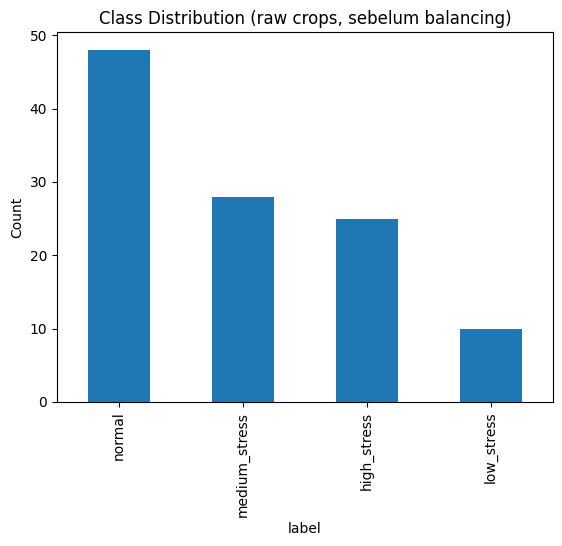

In [14]:
train_df["label"].value_counts()

train_df["label"].value_counts().plot(kind="bar")
plt.title("Class Distribution (raw crops, sebelum balancing)")
plt.ylabel("Count")
plt.show()


In [15]:
train_df[["x","y","w","h"]] = pd.DataFrame(
    train_df["bbox"].tolist(),
    index=train_df.index
)
train_df["bbox_area"] = train_df["w"] * train_df["h"]
train_df.head()


,id_x,image_id,category_id,bbox,iscrowd,area,segmentation,label,id_y,file_name,width,height,x,y,w,h,bbox_area
0,1,0,1,"[130.75, 105.75, 309.5, 400.5]",0,123954.75,[],high_stress,0,hs01_jpeg.rf.853acf3a6190a72bed4a9811fa48e856.jpg,640,640,130.75,105.75,309.5,400.5,123954.75
1,2,1,1,"[100.5, 25.75, 306, 527.5]",0,161415.00,[],high_stress,1,high-23-_jpg.rf.2c66ea904fb44ef9f692d935117c1e...,640,640,100.50,25.75,306.0,527.5,161415.00
2,3,1,1,"[320.25, 21, 85.5, 156]",0,13338.00,[],high_stress,1,high-23-_jpg.rf.2c66ea904fb44ef9f692d935117c1e...,640,640,320.25,21.00,85.5,156.0,13338.00
3,4,2,3,"[191, 0, 250, 640]",0,160000.00,[],medium_stress,2,medium-3-_jpg.rf.e1ede1cff5e00c5e6d85994a4d8c0...,640,640,191.00,0.00,250.0,640.0,160000.00
4,5,2,3,"[190.25, 0.25, 88.5, 181.5]",0,16062.75,[],medium_stress,2,medium-3-_jpg.rf.e1ede1cff5e00c5e6d85994a4d8c0...,640,640,190.25,0.25,88.5,181.5,16062.75


In [16]:
train_df["image_path"] = train_df["file_name"].apply(
    lambda x: os.path.join(TRAIN_DIR, x)
)
train_df.head()


,id_x,image_id,category_id,bbox,iscrowd,area,segmentation,label,id_y,file_name,width,height,x,y,w,h,bbox_area,image_path
0,1,0,1,"[130.75, 105.75, 309.5, 400.5]",0,123954.75,[],high_stress,0,hs01_jpeg.rf.853acf3a6190a72bed4a9811fa48e856.jpg,640,640,130.75,105.75,309.5,400.5,123954.75,E:\Magang DSC\Code - Image Classification Work...
1,2,1,1,"[100.5, 25.75, 306, 527.5]",0,161415.00,[],high_stress,1,high-23-_jpg.rf.2c66ea904fb44ef9f692d935117c1e...,640,640,100.50,25.75,306.0,527.5,161415.00,E:\Magang DSC\Code - Image Classification Work...
2,3,1,1,"[320.25, 21, 85.5, 156]",0,13338.00,[],high_stress,1,high-23-_jpg.rf.2c66ea904fb44ef9f692d935117c1e...,640,640,320.25,21.00,85.5,156.0,13338.00,E:\Magang DSC\Code - Image Classification Work...
3,4,2,3,"[191, 0, 250, 640]",0,160000.00,[],medium_stress,2,medium-3-_jpg.rf.e1ede1cff5e00c5e6d85994a4d8c0...,640,640,191.00,0.00,250.0,640.0,160000.00,E:\Magang DSC\Code - Image Classification Work...
4,5,2,3,"[190.25, 0.25, 88.5, 181.5]",0,16062.75,[],medium_stress,2,medium-3-_jpg.rf.e1ede1cff5e00c5e6d85994a4d8c0...,640,640,190.25,0.25,88.5,181.5,16062.75,E:\Magang DSC\Code - Image Classification Work...


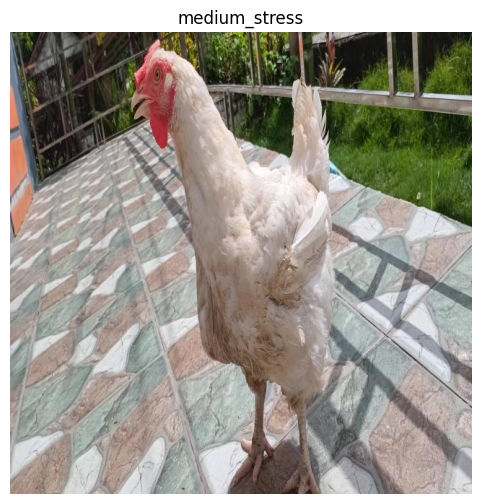

In [17]:
sample = train_df.sample(1).iloc[0]

img = Image.open(sample.image_path)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.title(sample.label)
plt.show()


## 3. Quality Check Gambar Mentah (RGB, ukuran, file rusak, blur)

Dicek di gambar **mentah** (`WORK_DIR/train`, `valid`, `test` — sebelum di-crop), supaya ketahuan dari awal kalau ada:
- File yang gagal/tidak bisa dibuka (corrupt)
- Gambar bukan RGB (misal grayscale/CMYK/RGBA) — ini tidak akan bikin pipeline crash karena langkah crop di bawah sudah pakai `.convert("RGB")`, tapi tetap penting diketahui (bisa indikasi sumber data campuran)
- **Mismatch ukuran**: lebar/tinggi aktual file vs yang tercatat di `_annotations.coco.json`. Ini penting karena normalisasi koordinat bbox untuk YOLO (`export_yolo_split`) memakai `width`/`height` dari metadata COCO, bukan dari file aslinya — kalau beda, bbox yang dihasilkan akan salah tanpa ada error yang muncul
- Gambar yang kemungkinan blur (pakai variance of Laplacian — angka kecil = makin blur)

File yang corrupt di split `train` akan otomatis dikeluarkan dari `train_df` di cell berikutnya (supaya proses crop+split tidak crash), dengan print log yang jelas file mana yang dibuang.

In [18]:
def check_image_quality(images_df, folder, split_name):
    rows = []
    for _, r in images_df.iterrows():
        path = os.path.join(folder, r["file_name"])
        record = {
            "file_name": r["file_name"],
            "split": split_name,
            "meta_width": r.get("width"),
            "meta_height": r.get("height"),
        }
        try:
            img = Image.open(path)
            img.load()  # paksa baca seluruh file, supaya file truncated/corrupt ketahuan di sini
            record["corrupt"] = False
            record["mode"] = img.mode
            record["actual_width"], record["actual_height"] = img.size
            record["size_mismatch"] = (
                record["actual_width"] != record["meta_width"]
                or record["actual_height"] != record["meta_height"]
            )
            gray = np.array(img.convert("L"), dtype=np.float64)
            lap = (
                -4 * gray
                + np.roll(gray, 1, axis=0) + np.roll(gray, -1, axis=0)
                + np.roll(gray, 1, axis=1) + np.roll(gray, -1, axis=1)
            )
            record["laplacian_var"] = lap.var()
        except Exception as e:
            record.update({
                "corrupt": True, "mode": None,
                "actual_width": None, "actual_height": None,
                "size_mismatch": None, "laplacian_var": None,
                "error": str(e),
            })
        rows.append(record)
    return pd.DataFrame(rows)

quality_train = check_image_quality(train_images, TRAIN_DIR, "train")
quality_valid = check_image_quality(valid_images, VALID_DIR, "valid")
quality_test  = check_image_quality(test_images, TEST_DIR, "test")

quality_df = pd.concat([quality_train, quality_valid, quality_test], ignore_index=True)
print("Total gambar dicek:", len(quality_df))


Total gambar dicek: 51


In [19]:
# --- File corrupt ---
n_corrupt = int(quality_df["corrupt"].sum())
print(f"File corrupt/gagal dibuka: {n_corrupt}")
if n_corrupt > 0:
    display(quality_df.loc[quality_df["corrupt"], ["file_name", "split", "error"]])


File corrupt/gagal dibuka: 0


In [20]:
# --- Mode warna (RGB vs non-RGB) ---
print("Distribusi mode warna:")
display(quality_df["mode"].value_counts(dropna=False))

non_rgb = quality_df[(quality_df["mode"].notna()) & (quality_df["mode"] != "RGB")]
print(f"\nGambar non-RGB: {len(non_rgb)} dari {quality_df['mode'].notna().sum()} yang berhasil dibuka")
if len(non_rgb) > 0:
    display(non_rgb[["file_name", "split", "mode"]].head(20))


Distribusi mode warna:


mode
RGB    51
Name: count, dtype: int64


Gambar non-RGB: 0 dari 51 yang berhasil dibuka


In [21]:
# --- Mismatch ukuran: metadata COCO vs file aktual ---
mismatch = quality_df[quality_df["size_mismatch"] == True]
print(f"Gambar dengan ukuran aktual != metadata COCO: {len(mismatch)}")
if len(mismatch) > 0:
    display(mismatch[["file_name", "split", "meta_width", "meta_height", "actual_width", "actual_height"]].head(20))
    print("\n>> PERHATIAN: kalau ada baris di atas, normalisasi bbox YOLO untuk file itu perlu diperbaiki")
    print("   (pakai actual_width/actual_height, bukan meta_width/meta_height) sebelum export_yolo_split dijalankan.")


Gambar dengan ukuran aktual != metadata COCO: 0


Statistik ukuran aktual (width x height, px):


,actual_width,actual_height
count,51.0,51.0
mean,640.0,640.0
std,0.0,0.0
min,640.0,640.0
25%,640.0,640.0
50%,640.0,640.0
75%,640.0,640.0
max,640.0,640.0


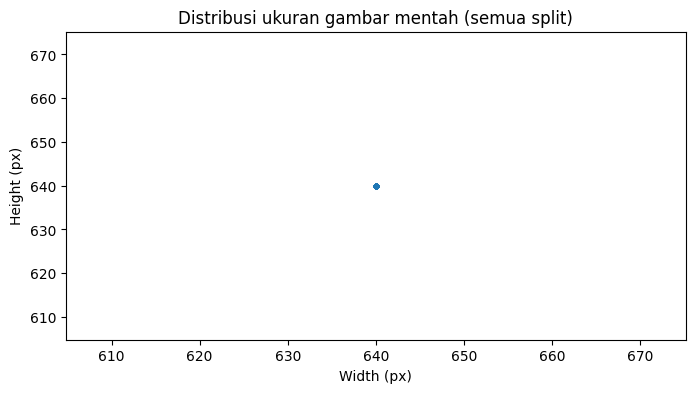

In [22]:
# --- Statistik ukuran gambar ---
print("Statistik ukuran aktual (width x height, px):")
display(quality_df[["actual_width", "actual_height"]].describe())

plt.figure(figsize=(8, 4))
plt.scatter(quality_df["actual_width"], quality_df["actual_height"], alpha=0.3, s=10)
plt.xlabel("Width (px)")
plt.ylabel("Height (px)")
plt.title("Distribusi ukuran gambar mentah (semua split)")
plt.show()


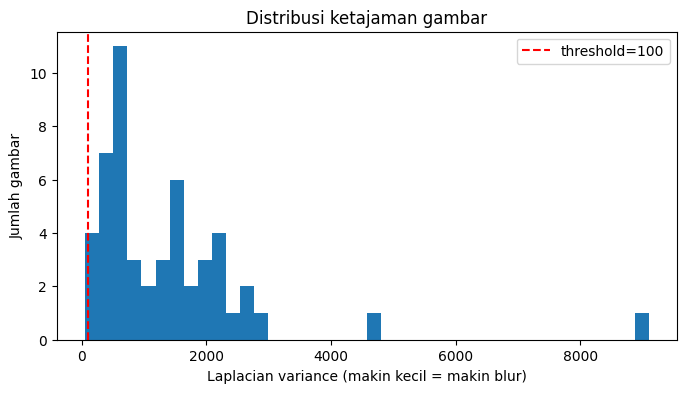

Gambar yang kemungkinan blur (Laplacian var < 100): 3 dari 51


,file_name,split,laplacian_var
4,s3_jpg.rf.0baa582ee2b5d7a62f8c71050fd23891.jpg,train,51.265327
14,73_NormalChicken_jpg.rf.8d50ceda103355d3d7bed4...,train,74.135522
48,IMG_-_-_jpg.rf.ac466c0d3196deb463c628abc21cf3f...,valid,77.398359



>> BLUR_THRESHOLD di atas cuma nilai awal umum, bukan hasil kalibrasi ke dataset ini.
   Cek dulu beberapa contoh gambar di 'blurry' secara visual, baru putuskan apakah mau dibuang atau tetap dipakai.


In [23]:
# --- Deteksi blur (variance of Laplacian) ---
BLUR_THRESHOLD = 100  # ambang umum yang sering dipakai; sesuaikan setelah lihat histogram di bawah

plt.figure(figsize=(8, 4))
plt.hist(quality_df["laplacian_var"].dropna(), bins=40)
plt.axvline(BLUR_THRESHOLD, color="red", linestyle="--", label=f"threshold={BLUR_THRESHOLD}")
plt.xlabel("Laplacian variance (makin kecil = makin blur)")
plt.ylabel("Jumlah gambar")
plt.legend()
plt.title("Distribusi ketajaman gambar")
plt.show()

blurry = quality_df[quality_df["laplacian_var"] < BLUR_THRESHOLD]
print(f"Gambar yang kemungkinan blur (Laplacian var < {BLUR_THRESHOLD}): "
      f"{len(blurry)} dari {quality_df['laplacian_var'].notna().sum()}")
display(blurry[["file_name", "split", "laplacian_var"]].sort_values("laplacian_var").head(20))
print("\n>> BLUR_THRESHOLD di atas cuma nilai awal umum, bukan hasil kalibrasi ke dataset ini.")
print("   Cek dulu beberapa contoh gambar di 'blurry' secara visual, baru putuskan apakah mau dibuang atau tetap dipakai.")


### Perbaikan Blur — Laplacian Sharpening (bukan langsung dibuang)

Alih-alih langsung membuang gambar yang terdeteksi blur, dicoba diperbaiki dulu pakai **Laplacian sharpening** (kernel penajam berbasis Laplacian) — konsisten dengan filosofi "perbaiki dulu, baru skip kalau masih buruk" di dokumen alur. `laplacian_var` di `quality_df` di-update dengan nilai setelah sharpening, supaya cell-cell berikutnya (termasuk keputusan buang/tidak) memakai kondisi gambar yang sudah diperbaiki.

In [24]:
# Kernel sharpening klasik = identity + Laplacian (menonjolkan tepi/detail yang hilang akibat blur)
SHARPEN_KERNEL = np.array([[0, -1, 0],
                            [-1, 5, -1],
                            [0, -1, 0]])

def laplacian_sharpen(img_bgr):
    return cv2.filter2D(img_bgr, -1, SHARPEN_KERNEL)

split_dirs = {"train": TRAIN_DIR, "valid": VALID_DIR, "test": TEST_DIR}
blurry_files = quality_df.loc[quality_df["laplacian_var"] < BLUR_THRESHOLD, ["file_name", "split", "laplacian_var"]]
print(f"Menerapkan Laplacian sharpening pada {len(blurry_files)} gambar yang terdeteksi blur...")

sharpen_log = []
for _, r in blurry_files.iterrows():
    path = os.path.join(split_dirs[r["split"]], r["file_name"])
    img_bgr = cv2.imread(path)
    if img_bgr is None:
        continue  # file corrupt, sudah ditangani terpisah di cell berikutnya

    sharpened = laplacian_sharpen(img_bgr)
    lap_var_after = cv2.Laplacian(cv2.cvtColor(sharpened, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var()

    cv2.imwrite(path, sharpened)  # PATCH: overwrite salinan kerja (WORK_DIR), RAW_DIR asli tidak disentuh

    sharpen_log.append({
        "file_name": r["file_name"], "split": r["split"],
        "laplacian_var_before": r["laplacian_var"], "laplacian_var_after": lap_var_after,
        "membaik": lap_var_after > r["laplacian_var"],
        "masih_dibawah_threshold": lap_var_after < BLUR_THRESHOLD,
    })

sharpen_log_df = pd.DataFrame(sharpen_log)
if len(sharpen_log_df):
    display(sharpen_log_df)
    n_improved = int(sharpen_log_df["membaik"].sum())
    n_still_blurry = int(sharpen_log_df["masih_dibawah_threshold"].sum())
    print(f"\nMembaik setelah sharpening: {n_improved} dari {len(sharpen_log_df)}")
    print(f"Masih di bawah threshold walau sudah di-sharpen: {n_still_blurry} "
          f"-- kandidat kuat untuk tetap dikeluarkan (lihat cell berikutnya)")

    # Update laplacian_var di quality_df dgn nilai TERBARU (setelah sharpening), supaya cell selanjutnya konsisten
    for _, row in sharpen_log_df.iterrows():
        mask = (quality_df["file_name"] == row["file_name"]) & (quality_df["split"] == row["split"])
        quality_df.loc[mask, "laplacian_var"] = row["laplacian_var_after"]

    SHARPEN_LOG_PATH = os.path.join(WORK_DIR, "blur_sharpening_log.csv")
    sharpen_log_df.to_csv(SHARPEN_LOG_PATH, index=False)
    print("Log sharpening disimpan ke:", SHARPEN_LOG_PATH)
else:
    print("Tidak ada gambar yang perlu di-sharpen.")

Menerapkan Laplacian sharpening pada 3 gambar yang terdeteksi blur...


,file_name,split,laplacian_var_before,laplacian_var_after,membaik,masih_dibawah_threshold
0,s3_jpg.rf.0baa582ee2b5d7a62f8c71050fd23891.jpg,train,51.265327,624.235987,True,False
1,73_NormalChicken_jpg.rf.8d50ceda103355d3d7bed4...,train,74.135522,864.736021,True,False
2,IMG_-_-_jpg.rf.ac466c0d3196deb463c628abc21cf3f...,valid,77.398359,808.942050,True,False



Membaik setelah sharpening: 3 dari 3
Masih di bawah threshold walau sudah di-sharpen: 0 -- kandidat kuat untuk tetap dikeluarkan (lihat cell berikutnya)
Log sharpening disimpan ke: E:\Magang DSC\Code - Image Classification Workflow\Data_working\blur_sharpening_log.csv


In [25]:
# --- Keluarkan file corrupt DAN yang masih blur walau sudah di-sharpen, dari train_df ---
corrupt_train_files = set(quality_df.loc[(quality_df["split"] == "train") & (quality_df["corrupt"]), "file_name"])

# PATCH: laplacian_var di quality_df sudah di-update ke nilai SETELAH sharpening (cell sebelumnya),
# jadi ini benar-benar "masih blur walau sudah diperbaiki", bukan "blur sebelum diperbaiki".
still_blurry_train_files = set(
    quality_df.loc[
        (quality_df["split"] == "train")
        & (~quality_df["corrupt"])
        & (quality_df["laplacian_var"] < BLUR_THRESHOLD),
        "file_name",
    ]
)

exclude_train_files = corrupt_train_files | still_blurry_train_files

if exclude_train_files:
    before = len(train_df)
    train_df = train_df[~train_df["file_name"].isin(exclude_train_files)].reset_index(drop=True)
    after = len(train_df)
    print(f"Dikeluarkan {before - after} baris anotasi dari train_df:")
    if corrupt_train_files:
        print(f"  - corrupt/gagal dibuka ({len(corrupt_train_files)}):", sorted(corrupt_train_files))
    if still_blurry_train_files:
        print(f"  - masih blur walau sudah di-sharpen ({len(still_blurry_train_files)}):", sorted(still_blurry_train_files))
else:
    print("Tidak ada file corrupt atau masih-blur di split train, train_df tidak diubah.")


Tidak ada file corrupt atau masih-blur di split train, train_df tidak diubah.


## 3.5 Deteksi Sesi/Burst & Konsolidasi Label 4 → 2 Kelas (Balancing)
### (sesuai `alur_deteksi_stres_ayam.md` — BAGIAN A, STEP 2)

**Update:** analisis terhadap dataset asli (`Stressed_chicken_v19i_coco`) menunjukkan bukti konkret bahwa banyak citra berasal dari **sesi/burst capture yang sama** — bukan foto independen satu-satu seperti dugaan awal:
- Sebagian nama file memuat timestamp (`IMG_YYYYMMDD_HHMMSS`), dan beberapa berselisih **hanya beberapa detik** (jelas burst).
- Perceptual hashing (kemiripan visual) menemukan **~41% citra masuk cluster kemiripan tinggi** — termasuk 2 pasang yang identik 100% — terutama pada seri `high-N`, `medium-N`, `low-N` yang kemungkinan hasil ekstraksi frame berurutan.

Karena metadata `session_id`/`camera_id`/`kandang_id` asli **tidak tersedia** di `_annotations.coco.json`, `session_id` di bawah ini **dideteksi otomatis** dari data itu sendiri, dengan menggabungkan dua sinyal:
1. **Perceptual hashing (pHash)** — citra dengan kemiripan visual tinggi (hamming distance kecil) dikelompokkan sebagai sesi/burst yang sama.
2. **Timestamp dari nama file** (kalau ada, format `IMG_YYYYMMDD_HHMMSS`) — citra yang diambil berselisih pendek (≤ `SESSION_TIME_GAP_SEC`) digabung ke sesi yang sama, sebagai sinyal tambahan di luar kemiripan visual murni.

Hasil clustering ini dipakai sebagai `session_id` pengganti `file_name` untuk **balancing (undersampling seimbang)** dan **split train/val/test** — memastikan seluruh crop dari sesi/burst yang sama selalu berada di kelompok kelas & subset yang sama (tidak pernah tersebar), sesuai catatan no-leakage di dokumen alur.

**Prosedur balancing (tetap sama seperti sebelumnya, level unit-nya saja yang diperbaiki menjadi `session_id`):**
1. Ambil seluruh sesi berlabel dominan `normal` → hitung jumlahnya, sebut **N**.
2. Gabungkan seluruh sesi dari 3 kelas sisanya (`low_stress + medium_stress + high_stress`) menjadi satu pool kandidat `stress`.
3. Sampling **acak** dari pool tersebut sebanyak **N** sesi, proporsional/stratified terhadap `low_stress`, `medium_stress`, `high_stress`.
4. Hasil akhir: dataset biner seimbang di level sesi — `not_stress` (N sesi) vs `stress` (N sesi, campuran ketiga level).
5. Sisa sesi dari pool `stress` yang tidak terpakai **disimpan terpisah** (bukan dibuang).

> **Catatan jujur soal keterbatasan:** ini tetap heuristik (bukan `session_id` asli dari metadata pengambilan data), jadi ada kemungkinan kecil false-positive/negative pada clustering. Kalau nanti tersedia metadata sesi/video sesungguhnya, ganti langsung bagian *deteksi sesi* di bawah dengan kolom tersebut — bagian balancing & split setelahnya tidak perlu diubah karena sudah bekerja di level `session_id` generik.

In [26]:
# === Deteksi session_id/burst dari data itu sendiri (phash + timestamp nama file) ===
# Diperlukan supaya balancing & split di bawah tidak memecah crop dari sesi/burst yang sama
# ke kelompok kelas / subset yang berbeda (lihat catatan di markdown di atas).

import re
from datetime import datetime

try:
    import imagehash
except ImportError:
    %pip install -q imagehash
    import imagehash

SESSION_PHASH_THRESHOLD = 10   # hamming distance pHash <= ini dianggap sesi/burst yang sama
SESSION_TIME_GAP_SEC = 120     # kalau ada timestamp di nama file, gap <= ini (detik) juga digabung sesi

unique_files = train_df["file_name"].unique().tolist()

# --- 1) Hitung pHash tiap citra unik ---
file_hash = {}
for fname in unique_files:
    path = os.path.join(TRAIN_DIR, fname)
    file_hash[fname] = imagehash.phash(Image.open(path))

# --- 2) Ekstrak timestamp dari nama file (kalau ada pola IMG_YYYYMMDD_HHMMSS) ---
ts_pattern = re.compile(r"IMG_(\d{8})_(\d{6})")
file_timestamp = {}
for fname in unique_files:
    m = ts_pattern.search(fname)
    if m:
        file_timestamp[fname] = datetime.strptime(m.group(1) + m.group(2), "%Y%m%d%H%M%S")

# --- 3) Union-Find: gabungkan file yang (a) pHash mirip, ATAU (b) timestamp berdekatan ---
parent = {f: f for f in unique_files}

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[ra] = rb

for i in range(len(unique_files)):
    for j in range(i + 1, len(unique_files)):
        f1, f2 = unique_files[i], unique_files[j]
        merged = False
        if (file_hash[f1] - file_hash[f2]) <= SESSION_PHASH_THRESHOLD:
            merged = True
        if not merged and f1 in file_timestamp and f2 in file_timestamp:
            gap = abs((file_timestamp[f1] - file_timestamp[f2]).total_seconds())
            if gap <= SESSION_TIME_GAP_SEC:
                merged = True
        if merged:
            union(f1, f2)

# --- 4) Beri nama session_id yang rapi (session_0001, session_0002, ...) ---
roots = sorted(set(find(f) for f in unique_files))
root_to_session_id = {root: f"session_{i+1:04d}" for i, root in enumerate(roots)}
file_to_session = {f: root_to_session_id[find(f)] for f in unique_files}

train_df["session_id"] = train_df["file_name"].map(file_to_session)

session_sizes = train_df.drop_duplicates("file_name")["session_id"].value_counts()
n_multi_file_sessions = (session_sizes > 1).sum()
print(f"Total citra unik: {len(unique_files)}")
print(f"Total session_id terdeteksi: {train_df['session_id'].nunique()}")
print(f"Sesi berisi >1 citra (burst terdeteksi): {n_multi_file_sessions}")
print(f"Threshold pHash <= {SESSION_PHASH_THRESHOLD}, gap timestamp <= {SESSION_TIME_GAP_SEC} detik")

session_map_df = (
    train_df.drop_duplicates("file_name")[["file_name", "session_id"]]
    .sort_values("session_id")
    .reset_index(drop=True)
)
display(session_map_df.head(20))

SESSION_MAP_PATH = os.path.join(WORK_DIR, "session_id_mapping.csv")
session_map_df.to_csv(SESSION_MAP_PATH, index=False)
print("Mapping file_name -> session_id disimpan ke:", SESSION_MAP_PATH)

Total citra unik: 47
Total session_id terdeteksi: 28
Sesi berisi >1 citra (burst terdeteksi): 12
Threshold pHash <= 10, gap timestamp <= 120 detik


,file_name,session_id
0,73_NormalChicken_jpg.rf.8d50ceda103355d3d7bed4...,session_0001
1,IMG_20250511_135123_jpg.rf.5a13604cc8ccf1f72e3...,session_0002
2,IMG_20250511_135019_jpg.rf.ff32e28ebe8ff7f447f...,session_0002
3,IMG_20250511_135949_jpg.rf.e5ccd5e52968fcd05e1...,session_0003
4,IMG_20250511_140154_jpg.rf.d692a8a6d8488cc873c...,session_0003
5,IMG_20250511_140105_jpg.rf.9d14fca27731cf6972d...,session_0003
6,IMG_20250511_185052_jpg.rf.74f4b8cc4aac1a728ff...,session_0004
7,IMG_20250511_185049_jpg.rf.7a0c68f7eefd524bb2d...,session_0004
8,IMG_20250512_094552_jpg.rf.e6659d8093bbb33d86e...,session_0005
9,IMG_20250512_094611_jpg.rf.eb5c7194b09338ee5dc...,session_0005


Mapping file_name -> session_id disimpan ke: E:\Magang DSC\Code - Image Classification Workflow\Data_working\session_id_mapping.csv


In [27]:
# === STEP 2 (MD): Konsolidasi label 4 kelas -> 2 kelas biner + balanced undersampling ===
# PATCH: level pengelompokan sekarang pakai session_id hasil deteksi (phash+timestamp) di atas,
# BUKAN lagi file_name mentah -- supaya crop dari sesi/burst yang sama tidak pernah terpisah.

BINARY_MAP = {
    "normal": "not_stress",
    "low_stress": "stress",
    "medium_stress": "stress",
    "high_stress": "stress",
}

def to_binary_label(orig_label):
    # fallback aman: apa pun selain 'normal' dianggap 'stress'
    return BINARY_MAP.get(orig_label, "stress")

train_df["label_orig"] = train_df["label"]  # simpan label 4-kelas asli untuk referensi/log
train_df["label_stres_binary"] = train_df["label_orig"].map(to_binary_label)

# Level pengelompokan: session_id (hasil clustering phash + timestamp)
def _dominant_nonstress_free_label(labels):
    labels = list(labels)
    if set(labels) == {"normal"}:
        return "normal"
    non_normal = [l for l in labels if l != "normal"]
    return pd.Series(non_normal).mode().iat[0]

session_dominant_label = train_df.groupby("session_id")["label_orig"].agg(_dominant_nonstress_free_label)

no_files = session_dominant_label[session_dominant_label == "normal"].index.tolist()
stress_files_by_sub = {
    sub: session_dominant_label[session_dominant_label == sub].index.tolist()
    for sub in ["low_stress", "medium_stress", "high_stress"]
}

N = len(no_files)
print(f"N (jumlah sesi 'normal' / not_stress) = {N}")
for sub, files in stress_files_by_sub.items():
    print(f"  pool '{sub}': {len(files)} sesi")

random.seed(SEED)

# Sampling proporsional/stratified dari pool stress sebanyak N total
pool_sizes = {sub: len(f) for sub, f in stress_files_by_sub.items()}
total_pool = sum(pool_sizes.values())

sampled_stress_files = []
remaining_quota = N
sub_names = list(stress_files_by_sub.keys())
for i, sub in enumerate(sub_names):
    files = stress_files_by_sub[sub]
    if i == len(sub_names) - 1:
        quota = remaining_quota  # sub-kelas terakhir ambil sisa kuota, hindari rounding error
    else:
        quota = round(N * pool_sizes[sub] / total_pool) if total_pool > 0 else 0
        quota = min(quota, remaining_quota)
    chosen = random.sample(files, min(quota, len(files)))
    sampled_stress_files.extend(chosen)
    remaining_quota -= len(chosen)

# Kalau kuota belum genap N (salah satu sub-kelas kehabisan pool), tambal dari sisa pool manapun yang masih ada
if remaining_quota > 0:
    leftover_candidates = [f for files in stress_files_by_sub.values() for f in files if f not in sampled_stress_files]
    extra = random.sample(leftover_candidates, min(remaining_quota, len(leftover_candidates)))
    sampled_stress_files.extend(extra)

reserved_stress_files = [f for files in stress_files_by_sub.values() for f in files if f not in sampled_stress_files]

print(f"\nTerpilih untuk kelas 'stress' (seimbang dgn N={N}): {len(sampled_stress_files)} sesi")
print(f"Sisa pool 'stress' yang TIDAK terpakai (disimpan terpisah): {len(reserved_stress_files)} sesi")

selected_sessions = set(no_files) | set(sampled_stress_files)
reserved_df = train_df[train_df["session_id"].isin(reserved_stress_files)].copy()  # PATCH: disimpan, bukan dibuang
train_df = train_df[train_df["session_id"].isin(selected_sessions)].reset_index(drop=True)

# Log jumlah citra per kelas asli yang terpakai vs tersisa
log_rows = []
for sub in ["normal", "low_stress", "medium_stress", "high_stress"]:
    if sub == "normal":
        used, total = len(no_files), len(no_files)
    else:
        used = len([f for f in sampled_stress_files if f in stress_files_by_sub[sub]])
        total = len(stress_files_by_sub[sub])
    log_rows.append({"kelas_asli": sub, "sesi_terpakai": used, "sesi_tersisa": total - used, "total_sesi": total})
balancing_log_df = pd.DataFrame(log_rows)
display(balancing_log_df)

# Jadikan label biner sebagai kolom kerja utama ("label") supaya seluruh cell berikutnya
# (crop per kelas, split, folder kelas, dataset YOLO) otomatis memakai skema 2 kelas.
train_df["label"] = train_df["label_stres_binary"]

print("\nDistribusi akhir (biner, sebelum split 70/15/15):")
display(train_df["label"].value_counts())

BALANCING_LOG_PATH = os.path.join(WORK_DIR, "label_balancing_log.csv")
balancing_log_df.to_csv(BALANCING_LOG_PATH, index=False)
RESERVED_STRESS_PATH = os.path.join(WORK_DIR, "reserved_stress_pool.csv")
reserved_df.to_csv(RESERVED_STRESS_PATH, index=False)
print("Log balancing disimpan ke:", BALANCING_LOG_PATH)
print("Pool 'stress' sisa (tidak dibuang) disimpan ke:", RESERVED_STRESS_PATH)


N (jumlah sesi 'normal' / not_stress) = 9
  pool 'low_stress': 3 sesi
  pool 'medium_stress': 9 sesi
  pool 'high_stress': 7 sesi

Terpilih untuk kelas 'stress' (seimbang dgn N=9): 9 sesi
Sisa pool 'stress' yang TIDAK terpakai (disimpan terpisah): 10 sesi


,kelas_asli,sesi_terpakai,sesi_tersisa,total_sesi
0,normal,9,0,9
1,low_stress,1,2,3
2,medium_stress,4,5,9
3,high_stress,4,3,7



Distribusi akhir (biner, sebelum split 70/15/15):


label
not_stress    40
stress        26
Name: count, dtype: int64

Log balancing disimpan ke: E:\Magang DSC\Code - Image Classification Workflow\Data_working\label_balancing_log.csv
Pool 'stress' sisa (tidak dibuang) disimpan ke: E:\Magang DSC\Code - Image Classification Workflow\Data_working\reserved_stress_pool.csv


## 4. Crop bounding box + split train/valid/test — level `session_id` (PATCH: no-leakage)
### (sesuai `alur_deteksi_stres_ayam.md` — BAGIAN A, STEP 3)

Split sekarang dilakukan di level **`session_id`** (hasil deteksi sesi/burst di atas), bukan lagi di level index anotasi individual — supaya seluruh crop dari sesi/burst yang sama selalu jatuh ke subset (train/valid/test) yang sama. Proporsi tetap 70/15/15, stratified per kelas biner, seed sama seperti sebelumnya.

In [28]:
from sklearn.model_selection import train_test_split

DEST = os.path.join(WORK_DIR, "dataset")
if os.path.exists(DEST):
    shutil.rmtree(DEST)

classes = sorted(train_df["label"].unique())
for split in ["train", "valid", "test"]:
    for cls in classes:
        os.makedirs(os.path.join(DEST, split, cls), exist_ok=True)

random.seed(SEED)

def safe_group_split(items, test_size, random_state):
    """Fallback aman kalau jumlah sesi di suatu kelas terlalu sedikit untuk displit
    (train_test_split butuh minimal 2 anggota). Kalau tidak cukup, semua masuk 'train'
    dan diberi peringatan -- lebih baik daripada error atau leakage diam-diam."""
    if len(items) < 2:
        if items:
            print(f"  [!] Hanya {len(items)} sesi -- semua dipaksa masuk 'train' (tidak cukup utk split).")
        return items, []
    return train_test_split(items, test_size=test_size, random_state=random_state)

# PATCH (Step 3 MD): split di level session_id (bukan lagi index anotasi individual),
# supaya crop dari sesi/burst yang sama selalu berada di subset yang sama -- no leakage.
session_label = train_df.drop_duplicates("session_id").set_index("session_id")["label"]

split_assignment_session = {}
for cls in classes:
    cls_sessions = session_label.index[session_label == cls].tolist()
    print(f"Kelas '{cls}': {len(cls_sessions)} sesi")
    train_sess, temp_sess = safe_group_split(cls_sessions, test_size=0.3, random_state=SEED)
    valid_sess, test_sess = safe_group_split(temp_sess, test_size=0.5, random_state=SEED)
    for s in train_sess:
        split_assignment_session[s] = "train"
    for s in valid_sess:
        split_assignment_session[s] = "valid"
    for s in test_sess:
        split_assignment_session[s] = "test"

# Verifikasi: tiap session_id yang dipakai sudah punya assignment split (tidak ada yang terlewat)
assert train_df["session_id"].map(split_assignment_session).notna().all(), "Ada session_id tanpa assignment split!"

counter = {}
for idx, row in train_df.iterrows():
    split_name = split_assignment_session[row.session_id]

    img = Image.open(row.image_path).convert("RGB")
    x, y, w, h = int(row.x), int(row.y), int(row.w), int(row.h)
    crop = img.crop((x, y, x + w, y + h))

    cls = row.label
    counter.setdefault(cls, 0)
    counter[cls] += 1

    filename = f"{cls}_{counter[cls]:04d}.jpg"
    crop.save(os.path.join(DEST, split_name, cls, filename))

print("\nCrop + split (level session_id) selesai, langsung ke:", DEST)
print(counter)

# Distribusi crop per split x kelas (jumlah crop, bukan jumlah sesi)
split_counts = (
    train_df.assign(split=train_df["session_id"].map(split_assignment_session))
    .groupby(["split", "label"]).size()
)
display(split_counts)

Kelas 'not_stress': 9 sesi
Kelas 'stress': 9 sesi

Crop + split (level session_id) selesai, langsung ke: E:\Magang DSC\Code - Image Classification Workflow\Data_working\dataset
{'stress': 26, 'not_stress': 40}


split  label     
test   not_stress     7
       stress         4
train  not_stress    27
       stress        16
valid  not_stress     6
       stress         6
dtype: int64

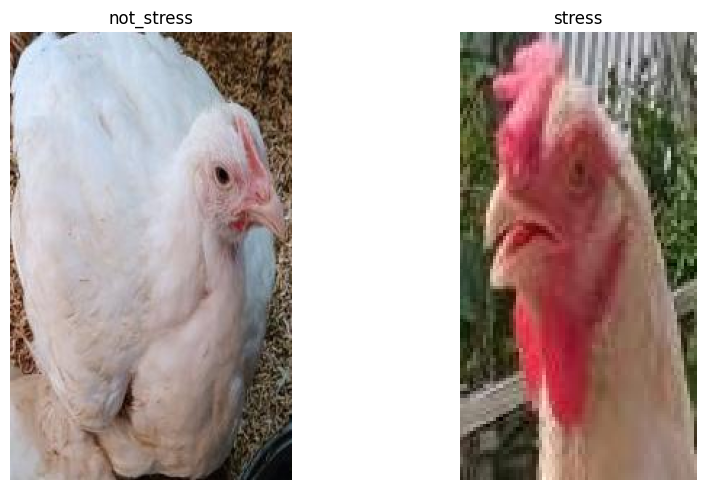

In [29]:
# Sample hasil crop per kelas (ambil dari dataset/train)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))  # PATCH: 2 kelas biner (not_stress/stress), bukan 4

for a, cls in zip(ax.flatten(), classes):
    cls_folder = os.path.join(DEST, "train", cls)
    img_name = random.choice(os.listdir(cls_folder))
    img = Image.open(os.path.join(cls_folder, img_name))
    a.imshow(img)
    a.set_title(cls)
    a.axis("off")

plt.tight_layout()
save_path = os.path.join(WORK_DIR, "sample_crop_classes.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()


In [30]:
from torchvision import transforms

augment = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1)),
])


In [31]:
train_class_counts = {
    cls: len(os.listdir(os.path.join(DEST, "train", cls)))
    for cls in os.listdir(os.path.join(DEST, "train"))
}
TARGET = max(train_class_counts.values())

print(pd.Series(train_class_counts))
print("TARGET per kelas (train):", TARGET)


not_stress    27
stress        16
dtype: int64
TARGET per kelas (train): 27


## 5. Balancing — hanya folder `train`

Loop augmentasi membaca dan menulis ke `DEST/train/<kelas>` saja. `valid` dan `test` tidak pernah jadi target di loop ini.

In [32]:
for cls in train_class_counts:

    folder = os.path.join(DEST, "train", cls)  # <-- hanya train
    images_in_folder = os.listdir(folder)
    need = TARGET - len(images_in_folder)

    print(cls, "perlu tambahan:", need)

    for i in range(need):

        img_name = random.choice(images_in_folder)

        img = Image.open(os.path.join(folder, img_name)).convert("RGB")

        aug = augment(img)

        aug.save(os.path.join(folder, f"aug_{i}_{img_name}"))


not_stress perlu tambahan: 0
stress perlu tambahan: 11


In [33]:
def count_split(split):
    folder = os.path.join(DEST, split)
    return {cls: len(os.listdir(os.path.join(folder, cls))) for cls in os.listdir(folder)}

print("Train (setelah balancing):")
display(pd.Series(count_split("train")))

print("\nValid (tidak diaugmentasi):")
display(pd.Series(count_split("valid")))

print("\nTest (tidak diaugmentasi):")
display(pd.Series(count_split("test")))

print("\n✅ valid & test tidak pernah disentuh oleh loop augmentasi/balancing di atas.")


Train (setelah balancing):


not_stress    27
stress        27
dtype: int64


Valid (tidak diaugmentasi):


not_stress    6
stress        6
dtype: int64


Test (tidak diaugmentasi):


not_stress    7
stress        4
dtype: int64


✅ valid & test tidak pernah disentuh oleh loop augmentasi/balancing di atas.


## 6. Dataset deteksi format YOLO (untuk model satu-tahap)

Untuk konfigurasi 1–3 (deteksi + klasifikasi sekaligus, termasuk DINOv2 & EfficientNetV2 sebagai backbone `FasterRCNN`), dibutuhkan dataset deteksi (gambar penuh + semua bounding box), bukan crop. Dibentuk dari `train_df`, serta `valid_ann`/`valid_images` dan `test_ann`/`test_images` yang sudah dibaca sebelumnya — ditulis ke `WORK_DIR/yolo_detect_dataset`, folder terpisah dari `dataset/`.

In [34]:
def build_split_df(images_df, ann_df):
    df = ann_df.copy()
    # PATCH (Step 2): konsolidasi langsung ke label biner, konsisten dengan train_df
    df["label"] = df["category_id"].map(label_map).map(to_binary_label)
    df = df.merge(
        images_df[["id", "file_name", "width", "height"]],
        left_on="image_id", right_on="id", how="left"
    )
    df[["x", "y", "w", "h"]] = pd.DataFrame(df["bbox"].tolist(), index=df.index)
    return df

valid_df = build_split_df(valid_images, valid_ann)
test_df  = build_split_df(test_images, test_ann)

# PATCH (Step 2): kelas final mengikuti skema biner (not_stress vs stress), bukan 4/5 kelas mentah COCO
class_names_sorted = ["not_stress", "stress"]
class_to_id = {name: i for i, name in enumerate(class_names_sorted)}
id_to_class = {i: name for name, i in class_to_id.items()}

print(class_to_id)


{'not_stress': 0, 'stress': 1}


In [35]:
YOLO_DIR = os.path.join(WORK_DIR, "yolo_detect_dataset")
if os.path.exists(YOLO_DIR):
    shutil.rmtree(YOLO_DIR)

def export_yolo_split(df, src_dir, split_name):
    img_out = os.path.join(YOLO_DIR, "images", split_name)
    lbl_out = os.path.join(YOLO_DIR, "labels", split_name)
    os.makedirs(img_out, exist_ok=True)
    os.makedirs(lbl_out, exist_ok=True)

    for file_name, group in df.groupby("file_name"):
        src_img = os.path.join(src_dir, file_name)
        if not os.path.exists(src_img):
            continue
        shutil.copy(src_img, os.path.join(img_out, file_name))

        width = group["width"].iloc[0]
        height = group["height"].iloc[0]

        lines = []
        for row in group.itertuples():
            cls_id = class_to_id[row.label]
            xc = (row.x + row.w / 2) / width
            yc = (row.y + row.h / 2) / height
            wn = row.w / width
            hn = row.h / height
            lines.append(f"{cls_id} {xc:.6f} {yc:.6f} {wn:.6f} {hn:.6f}")

        label_file = os.path.splitext(file_name)[0] + ".txt"
        with open(os.path.join(lbl_out, label_file), "w") as f:
            f.write("\n".join(lines))

export_yolo_split(train_df, TRAIN_DIR, "train")
export_yolo_split(valid_df, VALID_DIR, "valid")
export_yolo_split(test_df, TEST_DIR, "test")

data_yaml_content = {
    "path": YOLO_DIR,
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "names": {i: name for name, i in class_to_id.items()},
}

import yaml
with open(os.path.join(YOLO_DIR, "data.yaml"), "w") as f:
    yaml.dump(data_yaml_content, f, sort_keys=False)

print("YOLO-format detection dataset siap di:", YOLO_DIR)


YOLO-format detection dataset siap di: E:\Magang DSC\Code - Image Classification Workflow\Data_working\yolo_detect_dataset


## [DEBUG] Distribusi ukuran objek vs anchor sizes

Dicek **sebelum training model detektor**, supaya tahu lebih dulu apakah `AnchorGenerator` (dipakai config 2 & 3) cocok dengan ukuran objek ayam di dataset. Kalau histogram ukuran objek jauh dari garis anchor (merah), deteksi kemungkinan besar akan buruk walau training berjalan normal.

Statistik perkiraan sisi bbox (px):
count     66.000000
mean     222.786030
std      132.872677
min       64.604566
25%      114.063033
50%      185.740519
75%      299.083853
max      596.678305
dtype: float64

Anchor sizes yang dipakai (config 2 & 3): [32, 64, 128, 256, 512]


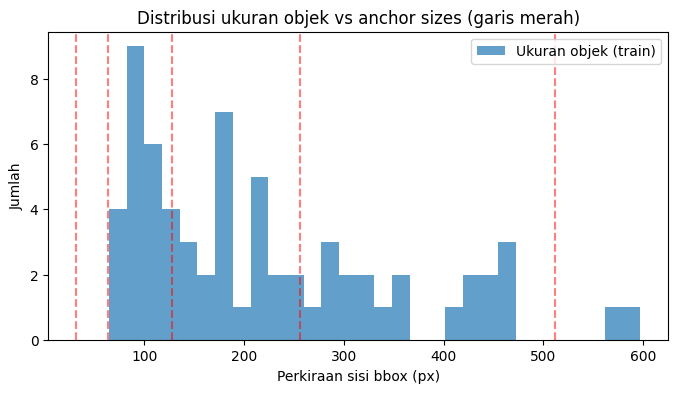


>> Kalau histogram menumpuk jauh dari garis merah, anchor size perlu disesuaikan
   (sesuaikan `sizes=(...)` di AnchorGenerator pada cell config 2 & 3 dengan rentang ini).


In [36]:
# === DEBUG: distribusi ukuran objek (train) vs anchor sizes ===
import numpy as np

all_areas = train_df["bbox_area"].values
all_side = np.sqrt(all_areas)  # perkiraan sisi bbox persegi ekuivalen (px)

print("Statistik perkiraan sisi bbox (px):")
print(pd.Series(all_side).describe())

anchor_sizes = [32, 64, 128, 256, 512]  # sama seperti di AnchorGenerator config 2 & 3
print("\nAnchor sizes yang dipakai (config 2 & 3):", anchor_sizes)

plt.figure(figsize=(8, 4))
plt.hist(all_side, bins=30, alpha=0.7, label="Ukuran objek (train)")
for a in anchor_sizes:
    plt.axvline(a, color="red", linestyle="--", alpha=0.5)
plt.xlabel("Perkiraan sisi bbox (px)")
plt.ylabel("Jumlah")
plt.title("Distribusi ukuran objek vs anchor sizes (garis merah)")
plt.legend()
plt.show()

print("\n>> Kalau histogram menumpuk jauh dari garis merah, anchor size perlu disesuaikan\n"
      "   (sesuaikan `sizes=(...)` di AnchorGenerator pada cell config 2 & 3 dengan rentang ini).")


## 7. Simpan artefak untuk notebook lanjutan (PATCH — bridging antar notebook)

Menyimpan semua path (`WORK_DIR`, `YOLO_DIR`, `DEST`, dll.), mapping kelas (`label_map`, `class_to_id`, `id_to_class`), dan dataframe (`train_df`, `valid_df`, `test_df`) ke satu file pickle. `02_models.ipynb` memuat file ini di awal supaya tidak perlu mengulang proses copy/quality-check/crop/split/augmentasi di atas.

`CLS_DIR` sudah dihapus dari sini karena foldernya (`classification_dataset_raw`) sudah tidak dibuat lagi.

In [37]:
import pickle

artifact_state = {
    "RAW_DIR": RAW_DIR, "WORK_DIR": WORK_DIR,
    "RAW_TRAIN_DIR": RAW_TRAIN_DIR, "RAW_VALID_DIR": RAW_VALID_DIR, "RAW_TEST_DIR": RAW_TEST_DIR,
    "TRAIN_DIR": TRAIN_DIR, "VALID_DIR": VALID_DIR, "TEST_DIR": TEST_DIR,
    "DEST": DEST, "YOLO_DIR": YOLO_DIR,
    "label_map": label_map, "class_to_id": class_to_id, "id_to_class": id_to_class,
    "class_names_sorted": class_names_sorted,
    "train_df": train_df, "valid_df": valid_df, "test_df": test_df,
}

ARTIFACT_PATH = os.path.join(WORK_DIR, "pipeline_artifacts.pkl")
with open(ARTIFACT_PATH, "wb") as f:
    pickle.dump(artifact_state, f)

print("Artefak notebook 1 disimpan ke:", ARTIFACT_PATH)
print("Notebook 2 (models) dan notebook 3 (evaluate) akan memuat file ini di awal.")


Artefak notebook 1 disimpan ke: E:\Magang DSC\Code - Image Classification Workflow\Data_working\pipeline_artifacts.pkl
Notebook 2 (models) dan notebook 3 (evaluate) akan memuat file ini di awal.
